# Decision Trees and Ensemble Learning

Dataset: https://github.com/gastonstat/CreditScoring

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline

from pathlib import Path
from pprint import pprint
from IPython.display import display

In [2]:
data = "https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-06-trees/CreditScoring.csv"
filename = data.split("/")[-1]

In [3]:
!pwsh -Command "curl -o ../datasets/$filename $data"

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0                              0
100 178.2k 100 178.2k   0      0 558.9k      0                              0
100 178.2k 100 178.2k   0      0 558.7k      0                              0
100 178.2k 100 178.2k   0      0 558.4k      0                              0


In [4]:
DATA_PATH = Path("../datasets").resolve() / filename

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(4455, 14)


,Status,Seniority,Home,Time,Age,Marital,Records,Job,Expenses,Income,Assets,Debt,Amount,Price
0,1,9,1,60,30,2,1,3,73,129,0,0,800,846
1,1,17,1,60,58,3,1,1,48,131,0,0,1000,1658
2,2,10,2,36,46,2,2,3,90,200,3000,0,2000,2985
3,1,0,1,60,24,1,1,1,63,182,2500,0,900,1325
4,1,0,1,36,26,1,1,1,46,107,0,0,310,910


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4455 entries, 0 to 4454
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Status     4455 non-null   int64
 1   Seniority  4455 non-null   int64
 2   Home       4455 non-null   int64
 3   Time       4455 non-null   int64
 4   Age        4455 non-null   int64
 5   Marital    4455 non-null   int64
 6   Records    4455 non-null   int64
 7   Job        4455 non-null   int64
 8   Expenses   4455 non-null   int64
 9   Income     4455 non-null   int64
 10  Assets     4455 non-null   int64
 11  Debt       4455 non-null   int64
 12  Amount     4455 non-null   int64
 13  Price      4455 non-null   int64
dtypes: int64(14)
memory usage: 487.4 KB


In [6]:
df.nunique()

Status          3
Seniority      47
Home            7
Time           11
Age            50
Marital         6
Records         2
Job             5
Expenses       94
Income        353
Assets        160
Debt          183
Amount        285
Price        1419
dtype: int64

## Data cleaning and preparation

In [7]:
df.columns = df.columns.str.lower()
df.columns

Index(['status', 'seniority', 'home', 'time', 'age', 'marital', 'records',
       'job', 'expenses', 'income', 'assets', 'debt', 'amount', 'price'],
      dtype='str')

In [8]:
df["status"].value_counts()

status
1    3200
2    1254
0       1
Name: count, dtype: int64

In [9]:
# Map of categorical columns/attributes/features

status_values = {
    1: "ok",
    2: "default",
    0: "unk"
}
df["status"] = df["status"].map(status_values)

home_values = {
    1: "rent",
    2: "owner",
    3: "private",
    4: "ignore",
    5: "parents",
    6: "other",
    0: "unk"
}
df["home"] = df["home"].map(home_values)

marital_values = {
    1: "single",
    2: "married",
    3: "widow",
    4: "separated",
    5: "divorced",
    0: "unk"
}
df["marital"] = df["marital"].map(marital_values)

records_values = {
    1: "no",
    2: "yes",
    0: "unk"
}
df["records"] = df["records"].map(records_values)

job_values = {
    1: "fixed",
    2: "part-time",
    3: "freelance",
    4: "others",
    5: "unk"
}
df["job"] = df["job"].map(job_values)

In [10]:
df.head()

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,9,rent,60,30,married,no,freelance,73,129,0,0,800,846
1,ok,17,rent,60,58,widow,no,fixed,48,131,0,0,1000,1658
2,default,10,owner,36,46,married,yes,freelance,90,200,3000,0,2000,2985
3,ok,0,rent,60,24,single,no,fixed,63,182,2500,0,900,1325
4,ok,0,rent,36,26,single,no,fixed,46,107,0,0,310,910


In [11]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,763317.0,1060341.0,404382.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,8703625.0,10217569.0,6344253.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3500.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,166.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,99999999.0,99999999.0,99999999.0,5000.0,11140.0


In [12]:
# Replace 99999999 (NaN)

for c in ["income", "assets", "debt"]:
    df[c] = df[c].replace(to_replace=99999999, value=np.nan)

In [13]:
df.describe().round()

,seniority,time,age,expenses,income,assets,debt,amount,price
count,4455.0,4455.0,4455.0,4455.0,4421.0,4408.0,4437.0,4455.0,4455.0
mean,8.0,46.0,37.0,56.0,131.0,5403.0,343.0,1039.0,1463.0
std,8.0,15.0,11.0,20.0,86.0,11573.0,1246.0,475.0,628.0
min,0.0,6.0,18.0,35.0,0.0,0.0,0.0,100.0,105.0
25%,2.0,36.0,28.0,35.0,80.0,0.0,0.0,700.0,1118.0
50%,5.0,48.0,36.0,51.0,120.0,3000.0,0.0,1000.0,1400.0
75%,12.0,60.0,45.0,72.0,165.0,6000.0,0.0,1300.0,1692.0
max,48.0,72.0,68.0,180.0,959.0,300000.0,30000.0,5000.0,11140.0


In [14]:
df.isna().sum()

status        0
seniority     0
home          0
time          0
age           0
marital       0
records       0
job           2
expenses      0
income       34
assets       47
debt         18
amount        0
price         0
dtype: int64

In [15]:
df.nunique()

status          3
seniority      47
home            7
time           11
age            50
marital         6
records         2
job             4
expenses       94
income        352
assets        159
debt          182
amount        285
price        1419
dtype: int64

In [16]:
cols_to_inspect = ["status", "home", "marital", "records", "job"]

for c in cols_to_inspect:
    display(df[c].value_counts())
    print("---")

status
ok         3200
default    1254
unk           1
Name: count, dtype: int64

---


home
owner      2107
rent        973
parents     783
other       319
private     247
ignore       20
unk           6
Name: count, dtype: int64

---


marital
married      3241
single        978
separated     130
widow          67
divorced       38
unk             1
Name: count, dtype: int64

---


records
no     3682
yes     773
Name: count, dtype: int64

---


job
fixed        2806
freelance    1024
part-time     452
others        171
Name: count, dtype: int64

---


In [17]:
# Drop the single record with status 'unknown'

df = df[df["status"] != "unk"].reset_index(drop=True)

In [18]:
df.shape

(4454, 14)

## Train-val-test split

In [19]:
SEED = 11

In [20]:
# Split data
df_full_train, df_test = train_test_split(
    df, 
    test_size=0.2, 
    random_state=SEED
)
df_train, df_val = train_test_split(
    df_full_train, 
    test_size=0.25, 
    random_state=SEED
)

# Reset indices
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

# Prepare target
y_train = (df_train["status"] == "default").astype("int").values
y_val = (df_val["status"] == "default").astype("int").values
y_test = (df_test["status"] == "default").astype("int").values

# Remove target values from feature matrices
df_train.drop("status", axis=1, inplace=True)
df_val.drop("status", axis=1, inplace=True)
df_test.drop("status", axis=1, inplace=True)

In [21]:
df_train.shape, df_val.shape, df_test.shape, df_full_train.shape

((2672, 13), (891, 13), (891, 13), (3563, 14))

In [22]:
df.shape

(4454, 14)

## Decision trees

In [23]:
# For demonstration consider a simple tree

def assess_risk(client):
    if client["records"] == "yes":
        if client["job"] == "part-time":
            return "default"
        else:
            return "ok"
    else:
        if client["assets"] > 6000:
            return "ok"
        else:
            return "default"

xi = df_train.iloc[-1].to_dict()
assess_risk(xi)

'ok'

Writing rules by hand doesn't scale. The point of the decision tree algorithm is that it learns these rules from data automatically.

In [24]:
train_dict = df_train.fillna(0).to_dict(orient="records")

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dict)

In [25]:
dt = DecisionTreeClassifier(random_state=SEED)
dt.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",11
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [26]:
# Check validation set

val_dict = df_val.fillna(0).to_dict(orient="records")
X_val = dv.transform(val_dict)

y_pred = dt.predict_proba(X_val)[:, 1]
roc_auc_score(y_val, y_pred)

0.655018648131554

In [27]:
# Double check on training set

y_pred = dt.predict_proba(X_train)[:, 1]
roc_auc_score(y_train, y_pred)

1.0

AUC of 1.0 on training but 0.65 on validation: the tree memorized the training data. It learned one specific rule per customer, so on the customers it has seen it's perfect - but these rules don't generalize to unseen customers. This is **overfitting**: memorizing the data but failing to generalize.

In [28]:
# Retrain by controlling the depth of tree

dt = DecisionTreeClassifier(max_depth=2, random_state=SEED)
dt.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",11
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [29]:
y_pred = dt.predict_proba(X_train)[:, 1]
auc = roc_auc_score(y_train, y_pred)
print(f"train = {auc}")

y_pred = dt.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
print(f"val = {auc}")

train = 0.7054989859726213
val = 0.6685264343319367


The training AUC went down, but the validation AUC went up. We traded some accuracy on known customers for the ability to generalize.

In [30]:
print(
    export_text(dt, feature_names=list(dv.get_feature_names_out()))
)

|--- records=no <= 0.50
|   |--- seniority <= 6.50
|   |   |--- class: 1
|   |--- seniority >  6.50
|   |   |--- class: 0
|--- records=no >  0.50
|   |--- job=part-time <= 0.50
|   |   |--- class: 0
|   |--- job=part-time >  0.50
|   |   |--- class: 1



In [31]:
# Some experiment in modifying the depth of tree

max_depths = np.arange(1, 11)
results = {}

for d in max_depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    dt.fit(X_train, y_train)

    y_pred_train = dt.predict_proba(X_train)[:, 1]
    auc_train = roc_auc_score(y_train, y_pred_train)
    
    y_pred_val = dt.predict_proba(X_val)[:, 1]
    auc_val = roc_auc_score(y_val, y_pred_val)

    results[d.item()] = (auc_train, auc_val)

In [32]:
pprint(results)

{1: (0.6282660131823559, 0.6058644740984719),
 2: (0.7054989859726213, 0.6685264343319367),
 3: (0.7761016984958594, 0.7389079944782155),
 4: (0.8164293560926146, 0.7612827250490422),
 5: (0.8433781899611289, 0.7669377103969388),
 6: (0.8745461523294462, 0.7583129495531714),
 7: (0.8998831051771731, 0.7452562301712237),
 8: (0.9241704692693369, 0.7363590128599453),
 9: (0.9475835868401781, 0.7130034390060788),
 10: (0.9640534336093741, 0.6863571964834951)}


For this particular dataset, the suitable max depth based on validation set is 5.

In [33]:
dt = DecisionTreeClassifier(max_depth=5, random_state=SEED)
dt.fit(X_train, y_train)

y_pred = dt.predict_proba(X_train)[:, 1]
auc = roc_auc_score(y_train, y_pred)
print(f"train = {auc}")

y_pred = dt.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
print(f"val = {auc}")

train = 0.8433781899611289
val = 0.7669377103969388


In [34]:
print(
    export_text(dt, feature_names=list(dv.get_feature_names_out()))
)

|--- records=no <= 0.50
|   |--- seniority <= 6.50
|   |   |--- amount <= 862.50
|   |   |   |--- seniority <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- seniority >  0.50
|   |   |   |   |--- income <= 50.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- income >  50.50
|   |   |   |   |   |--- class: 0
|   |   |--- amount >  862.50
|   |   |   |--- assets <= 8250.00
|   |   |   |   |--- job=fixed <= 0.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- job=fixed >  0.50
|   |   |   |   |   |--- class: 1
|   |   |   |--- assets >  8250.00
|   |   |   |   |--- income <= 132.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- income >  132.50
|   |   |   |   |   |--- class: 0
|   |--- seniority >  6.50
|   |   |--- income <= 103.50
|   |   |   |--- assets <= 4500.00
|   |   |   |   |--- time <= 54.00
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- time >  54.00
|   |   |   |   |   |--- class: 1
|   |   |   |--- assets >  4500.00
|   |   |   |   |--- i

## Decision tree learning algorithm

- Finding the best split for one column
- Finding the best split for the entire dataset
- Stopping criteria
- Decision tree learning algorithm

In [35]:
data = [
    [8000, 'default'],
    [2000, 'default'],
    [   0, 'default'],
    [5000, 'ok'],
    [5000, 'ok'],
    [4000, 'ok'],
    [9000, 'ok'],
    [3000, 'default'],
]

df_example = pd.DataFrame(data, columns=["assets", "status"])
df_example

,assets,status
0,8000,default
1,2000,default
2,0,default
3,5000,ok
4,5000,ok
5,4000,ok
6,9000,ok
7,3000,default


We want to build a decision stump - a tree with one condition, assets > T. The question is: which threshold T is the best?

In [36]:
Ts = df_example["assets"].sort_values().unique().tolist()
Ts

[0, 2000, 3000, 4000, 5000, 8000, 9000]

In [37]:
T = 4000
df_left = df_example[df_example.assets <= T]
df_right = df_example[df_example.assets > T]

display(df_left)
print("--- LEFT ---")
print(df_left["status"].value_counts(normalize=True))

display(df_right)
print("--- RIGHT ---")
print(df_right["status"].value_counts(normalize=True))

,assets,status
1,2000,default
2,0,default
5,4000,ok
7,3000,default


--- LEFT ---
status
default    0.75
ok         0.25
Name: proportion, dtype: float64


,assets,status
0,8000,default
3,5000,ok
4,5000,ok
6,9000,ok


--- RIGHT ---
status
ok         0.75
default    0.25
Name: proportion, dtype: float64


In [38]:
for T in Ts:
    print(f"THRESHOLD: {T}")
    df_left = df_example[df_example.assets <= T] # default
    df_right = df_example[df_example.assets > T] # ok

    print("--- LEFT ---")
    print(df_left["status"].value_counts(normalize=True))
    
    print("--- RIGHT ---")
    print(df_right["status"].value_counts(normalize=True))

    print()

THRESHOLD: 0
--- LEFT ---
status
default    1.0
Name: proportion, dtype: float64
--- RIGHT ---
status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64

THRESHOLD: 2000
--- LEFT ---
status
default    1.0
Name: proportion, dtype: float64
--- RIGHT ---
status
ok         0.666667
default    0.333333
Name: proportion, dtype: float64

THRESHOLD: 3000
--- LEFT ---
status
default    1.0
Name: proportion, dtype: float64
--- RIGHT ---
status
ok         0.8
default    0.2
Name: proportion, dtype: float64

THRESHOLD: 4000
--- LEFT ---
status
default    0.75
ok         0.25
Name: proportion, dtype: float64
--- RIGHT ---
status
ok         0.75
default    0.25
Name: proportion, dtype: float64

THRESHOLD: 5000
--- LEFT ---
status
default    0.5
ok         0.5
Name: proportion, dtype: float64
--- RIGHT ---
status
default    0.5
ok         0.5
Name: proportion, dtype: float64

THRESHOLD: 8000
--- LEFT ---
status
default    0.571429
ok         0.428571
Name: proportion, dtype: flo

In [39]:
data = [
    [8000, 3000, 'default'],
    [2000, 1000, 'default'],
    [   0, 1000, 'default'],
    [5000, 1000, 'ok'],
    [5000, 1000, 'ok'],
    [4000, 1000, 'ok'],
    [9000,  500, 'ok'],
    [3000, 2000, 'default'],
]

df_example = pd.DataFrame(data, columns=["assets", "debt", "status"])
df_example

,assets,debt,status
0,8000,3000,default
1,2000,1000,default
2,0,1000,default
3,5000,1000,ok
4,5000,1000,ok
5,4000,1000,ok
6,9000,500,ok
7,3000,2000,default


In [40]:
thresholds = {}

for c in ["assets", "debt"]:
    thresholds[c] = df_example[c].sort_values().unique().tolist()

thresholds

{'assets': [0, 2000, 3000, 4000, 5000, 8000, 9000],
 'debt': [500, 1000, 2000, 3000]}

In [41]:
for feature, Ts in thresholds.items():
    print('#####################')
    print(f"FEATURE: {feature}")
    for T in Ts:
        print(f"THRESHOLD: {T}")
        df_left = df_example[df_example[feature] <= T]
        df_right = df_example[df_example[feature] > T]

        # display(df_left)
        print("--- LEFT ---")
        print(df_left["status"].value_counts(normalize=True))
        
        # display(df_right)
        print("--- RIGHT ---")
        print(df_right["status"].value_counts(normalize=True))

        print()
    print('#####################')

#####################
FEATURE: assets
THRESHOLD: 0
--- LEFT ---
status
default    1.0
Name: proportion, dtype: float64
--- RIGHT ---
status
ok         0.571429
default    0.428571
Name: proportion, dtype: float64

THRESHOLD: 2000
--- LEFT ---
status
default    1.0
Name: proportion, dtype: float64
--- RIGHT ---
status
ok         0.666667
default    0.333333
Name: proportion, dtype: float64

THRESHOLD: 3000
--- LEFT ---
status
default    1.0
Name: proportion, dtype: float64
--- RIGHT ---
status
ok         0.8
default    0.2
Name: proportion, dtype: float64

THRESHOLD: 4000
--- LEFT ---
status
default    0.75
ok         0.25
Name: proportion, dtype: float64
--- RIGHT ---
status
ok         0.75
default    0.25
Name: proportion, dtype: float64

THRESHOLD: 5000
--- LEFT ---
status
default    0.5
ok         0.5
Name: proportion, dtype: float64
--- RIGHT ---
status
default    0.5
ok         0.5
Name: proportion, dtype: float64

THRESHOLD: 8000
--- LEFT ---
status
default    0.571429
ok        

```
FOR each feature in ALL_FEATURES:
    FIND all thresholds for the feature
    FOR each threshold in thresholds:
        SPLIT the dataset using "feature > threshold" condition
        COMPUTE the impurity of this split
SELECT the condition with the LOWEST IMPURITY
```

Stopping Criteria:

- The group is already pure: 0% impurity.
- The maximum depth has been reached.
- The group is smaller than the minimum size set for groups.
- The maximum number of leaves/terminal nodes has been reached.

## Decision trees tuning

- Selecting `max_depth`
- Selecting `min_samples_leaf`

DecisionTreeClassifier has many parameters - `criterion`, which is the impurity measure, `max_depth`, `min_samples_leaf`, and others. The two that matter most are:

- `max_depth` - the maximum number of levels. It limits how specific the rules can get.
- `min_samples_leaf` - the minimum number of samples in a leaf. It prevents the tree from creating leaves that cover just one or two customers.

Tuning means selecting the values that give the best score on the validation set - AUC in our case.

In [42]:
depths = [1, 2, 3, 4, 5, 6, 10, 15, 20, None]

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=SEED)
    dt.fit(X_train, y_train)

    y_pred = dt.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    print(f"{d} -> {auc:.3f}")

1 -> 0.606
2 -> 0.669
3 -> 0.739
4 -> 0.761
5 -> 0.767
6 -> 0.758
10 -> 0.686
15 -> 0.648
20 -> 0.655
None -> 0.655


Note: `None` means unlimited depth

In [43]:
optimal_max_depths = [4, 5, 6]
min_sample_size = [1, 5, 10, 15, 20, 500, 100, 200]
scores = []

for d in optimal_max_depths:
    for s in min_sample_size:
        dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=s, random_state=SEED)
        dt.fit(X_train, y_train)

        y_pred = dt.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, s, auc))

In [44]:
columns = ["max_depth", "min_samples_leaf", "auc"]
df_scores = pd.DataFrame(scores, columns=columns)
df_scores

,max_depth,min_samples_leaf,auc
0,4,1,0.761283
1,4,5,0.761283
2,4,10,0.761283
3,4,15,0.763726
4,4,20,0.760910
5,4,500,0.679842
6,4,100,0.755937
7,4,200,0.747260
8,5,1,0.766938
9,5,5,0.768173


In [45]:
df_scores_pivot = df_scores.pivot(
    index="min_samples_leaf",
    columns="max_depth",
    values="auc",
).round(3)

df_scores_pivot

max_depth,4,5,6
min_samples_leaf,,,
1,0.761,0.767,0.758
5,0.761,0.768,0.762
10,0.761,0.762,0.778
15,0.764,0.772,0.785
20,0.761,0.774,0.774
100,0.756,0.763,0.776
200,0.747,0.759,0.768
500,0.680,0.680,0.680


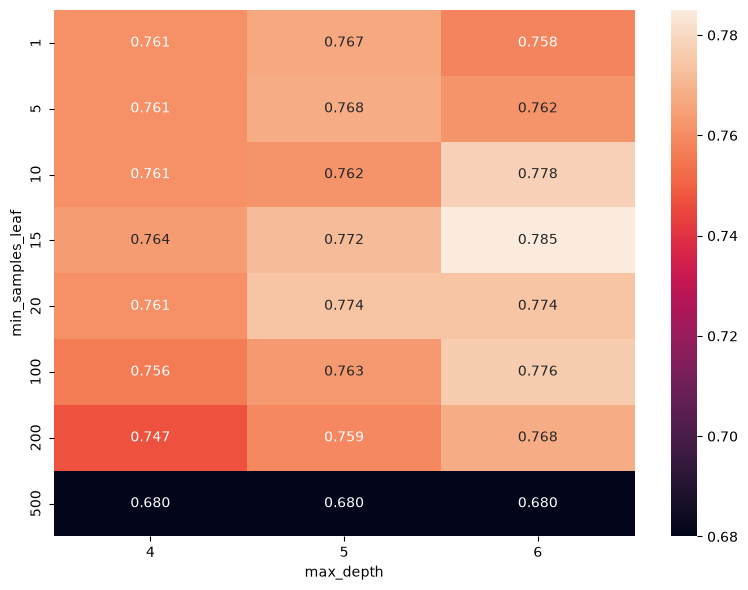

In [46]:
fig, ax = plt.subplots(figsize=(800, 600, "px"))

sns.heatmap(df_scores_pivot, annot=True, fmt=".3f", ax=ax)

plt.tight_layout()

Best combination (AUC = 0.785)

- `max_depth` = 6
- `min_samples_leaf` = 15

In [47]:
# Final tree

dt = DecisionTreeClassifier(
    max_depth=6, 
    min_samples_leaf=15, 
    random_state=SEED
)
dt.fit(X_train, y_train)

print(
    export_text(dt, feature_names=list(dv.get_feature_names_out()))
)

|--- records=no <= 0.50
|   |--- seniority <= 6.50
|   |   |--- amount <= 862.50
|   |   |   |--- price <= 925.00
|   |   |   |   |--- income <= 117.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- income >  117.50
|   |   |   |   |   |--- class: 1
|   |   |   |--- price >  925.00
|   |   |   |   |--- price <= 1382.00
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- price >  1382.00
|   |   |   |   |   |--- class: 0
|   |   |--- amount >  862.50
|   |   |   |--- assets <= 8250.00
|   |   |   |   |--- job=fixed <= 0.50
|   |   |   |   |   |--- assets <= 3425.00
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- assets >  3425.00
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- job=fixed >  0.50
|   |   |   |   |   |--- age <= 31.50
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- age >  31.50
|   |   |   |   |   |   |--- class: 1
|   |   |   |--- assets >  8250.00
|   |   |   |   |--- income <= 132.50
|   |   |   |   |   |--- class: 1
|

Importance of max_depth and min_samples_leaf

1. Controlling Overfitting: these parameters play a critical role in preventing overfitting.
- max_depth limits the tree's complexity, preventing it from growing too deep and memorizing the training data.
- min_samples_leaf ensures that leaf nodes have a sufficient number of samples, reducing the chance of creating nodes that are too specific to the training data.

2. Impact on Bias and Variance: They also affect the model's bias and variance.
- Increasing max_depth and decreasing min_samples_leaf can lead to a more complex model with lower bias but higher variance.
- Decreasing max_depth and increasing min_samples_leaf results in a simpler model with higher bias but lower variance.

## Ensemble learning and random forest

- Ensembling - Combining several models to make a prediction
- Random Forest - Ensemble of decision trees

In [48]:
scores = []

num_trees = range(10, 201, 10)

for n in num_trees:
    rf = RandomForestClassifier(n_estimators=n, random_state=SEED)
    rf.fit(X_train, y_train)

    y_pred = rf.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    scores.append((n, auc))

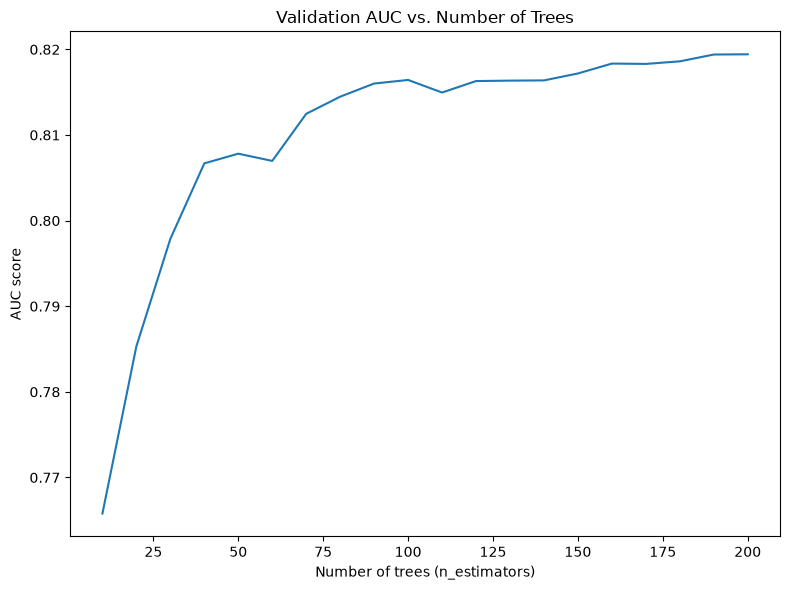

In [49]:
df_scores = pd.DataFrame(scores, columns=["n_estimators", "auc"])

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(df_scores["n_estimators"], df_scores["auc"])

ax.set_title("Validation AUC vs. Number of Trees")
ax.set_xlabel("Number of trees (n_estimators)")
ax.set_ylabel("AUC score")

plt.tight_layout()

As the number of trees (estimators) increases, the training time increases.

In [50]:
# Tuning max_depth

scores = []

num_trees = range(10, 201, 10)
depths = [5, 10, 15, 20]

for d in depths:
    for n in num_trees:
        rf = RandomForestClassifier(n_estimators=n, max_depth=d, random_state=SEED)
        rf.fit(X_train, y_train)
    
        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
    
        scores.append((d, n, auc))

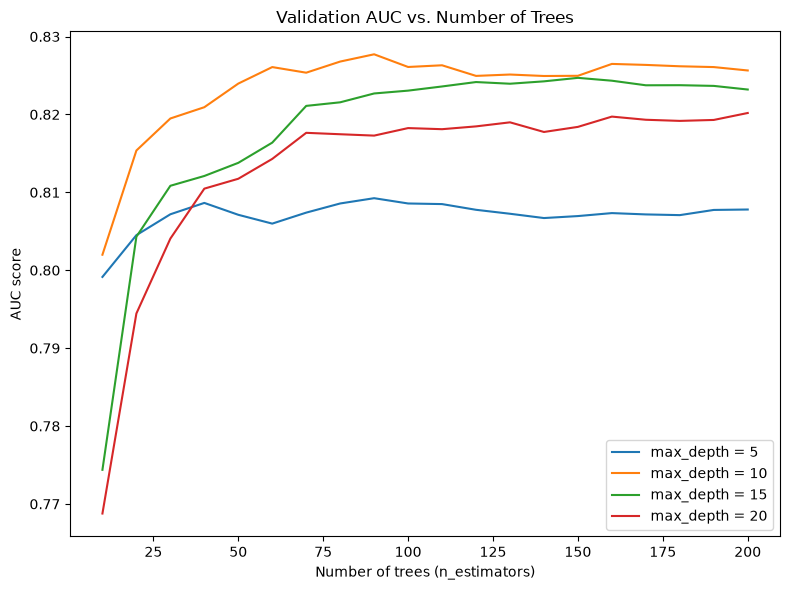

In [51]:
columns = ["max_depth", "n_estimators", "auc"]
df_scores = pd.DataFrame(scores, columns=columns)

fig, ax = plt.subplots(figsize=(8, 6))

depths = [5, 10, 15, 20]
for d in depths:
    df_subset = df_scores[df_scores["max_depth"] == d]
    ax.plot(df_subset["n_estimators"], df_subset["auc"], label=f"max_depth = {d}")

ax.legend()
ax.set_title("Validation AUC vs. Number of Trees")
ax.set_xlabel("Number of trees (n_estimators)")
ax.set_ylabel("AUC score")

plt.tight_layout()

Best `max_depth`: 10

In [52]:
# Tuning min_samples_leaf

scores = []

MAX_DEPTH = 10
num_trees = range(10, 201, 10)
min_sample_size = [1, 3, 5, 10, 50]

for s in min_sample_size:
    for n in num_trees:
        rf = RandomForestClassifier(
            n_estimators=n, 
            max_depth=MAX_DEPTH,
            min_samples_leaf=s,
            random_state=SEED
        )
        rf.fit(X_train, y_train)
    
        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
    
        scores.append((s, n, auc))

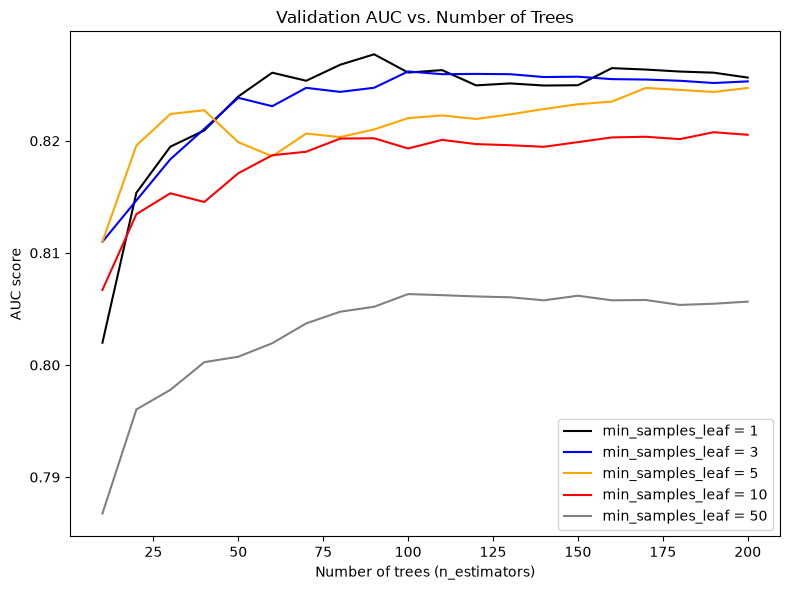

In [53]:
columns = ["min_samples_leaf", "n_estimators", "auc"]
df_scores = pd.DataFrame(scores, columns=columns)

fig, ax = plt.subplots(figsize=(8, 6))

colors = ["black", "blue", "orange", "red", "grey"]
min_sample_size = [1, 3, 5, 10, 50]
for s, col in zip(min_sample_size, colors):
    df_subset = df_scores[df_scores["min_samples_leaf"] == s]
    ax.plot(
        df_subset["n_estimators"], 
        df_subset["auc"], 
        color=col, 
        label=f"min_samples_leaf = {s}"
    )

ax.legend()
ax.set_title("Validation AUC vs. Number of Trees")
ax.set_xlabel("Number of trees (n_estimators)")
ax.set_ylabel("AUC score")

plt.tight_layout()

The curves with small values are relatively close to each other. Take `min_samples_leaf` = 3

In [54]:
# Final model

NUM_TREES = 200
MAX_DEPTH = 10
MIN_SAMPLES = 3

rf = RandomForestClassifier(
    n_estimators=NUM_TREES, 
    max_depth=MAX_DEPTH,
    min_samples_leaf=MIN_SAMPLES,
    random_state=SEED
)

rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",11
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap

Other useful parameters to look into:

- `max_features` - controls size of random feature subset for each tree
- `bootstrap` - controls whether each tree is trained on a randomly resampled copy of the data

Bootstrapping -> resampling technique where we sample the original data (with replacement) to create numerous subsets of it

## Gradient boosting and XGBoost

- In random forest, trees (models) are trained independently.
- In boosting, models are trained one by one where each next model fixes the errors of the previous ones.

Note on XGBoost:

XGBoost does not work with NumPy arrays directly. Instead, we wrap the data into a special data structure called DMatrix, which is optimized for training XGBoost models. We create it from the feature matrix and the target array, and also pass the feature names.

In [55]:
dv.get_feature_names_out()

array(['age', 'amount', 'assets', 'debt', 'expenses', 'home=ignore',
       'home=other', 'home=owner', 'home=parents', 'home=private',
       'home=rent', 'home=unk', 'income', 'job', 'job=fixed',
       'job=freelance', 'job=others', 'job=part-time', 'marital=divorced',
       'marital=married', 'marital=separated', 'marital=single',
       'marital=unk', 'marital=widow', 'price', 'records=no',
       'records=yes', 'seniority', 'time'], dtype=object)

In [56]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [57]:
# Training first model

MAX_DEPTH = 6
MIN_SAMPLES = 1

xgb_params = {
    "eta": 0.3,
    "max_depth": MAX_DEPTH,
    "min_child_weight": MIN_SAMPLES,
    
    "objective": "binary:logistic",
    "nthread": 8,
    
    "seed": SEED,
    "verbosity": 1
}

model = xgb.train(xgb_params, dtrain, num_boost_round=10)

- `eta` is the learning rate - how large the correction each next model applies is.
- `max_depth` and `min_child_weight` control the size of the trees, same as `max_depth` and `min_samples_leaf` in decision trees and random forest.
- `objective` is the task we are solving - `binary:logistic` is binary classification, and it makes the model output probabilities.
- `num_boost_round` - number of boosting rounds - the number of models in our sequence

In [58]:
y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

0.8156256811411687

In [59]:
# Performance monitoring

watchlist = [(dtrain, "train"), (dval, "val")]

In [60]:
%%capture output

MAX_DEPTH = 6
MIN_SAMPLES = 1

xgb_params = {
    "eta": 0.3,
    "max_depth": MAX_DEPTH,
    "min_child_weight": MIN_SAMPLES,
    
    "objective": "binary:logistic",
    "eval_metric": "auc",
    
    "nthread": 8,
    "seed": SEED,
    "verbosity": 1
}

model = xgb.train(
    xgb_params, 
    dtrain, 
    num_boost_round=200, 
    verbose_eval=5, 
    evals=watchlist
)

In [61]:
s = output.stdout

In [62]:
print(s[:400])

[0]	train-auc:0.86632	val-auc:0.77998
[5]	train-auc:0.93359	val-auc:0.81150
[10]	train-auc:0.95391	val-auc:0.82002
[15]	train-auc:0.97087	val-auc:0.82220
[20]	train-auc:0.97677	val-auc:0.82239
[25]	train-auc:0.98440	val-auc:0.82074
[30]	train-auc:0.98805	val-auc:0.82061
[35]	train-auc:0.99239	val-auc:0.81804
[40]	train-auc:0.99474	val-auc:0.81732
[45]	train-auc:0.99627	val-auc:0.81413
[50]	train-a


In [63]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split("\n"):
        it_line, train_line, val_line = line.split("\t")

        it = int(it_line.strip("[]"))
        train = float(train_line.split(":")[1])
        val = float(val_line.split(":")[1])

        results.append((it, train, val))

    columns = ["n_iter", "train_auc", "val_auc"]
    df_results = pd.DataFrame(results, columns=columns)

    return df_results

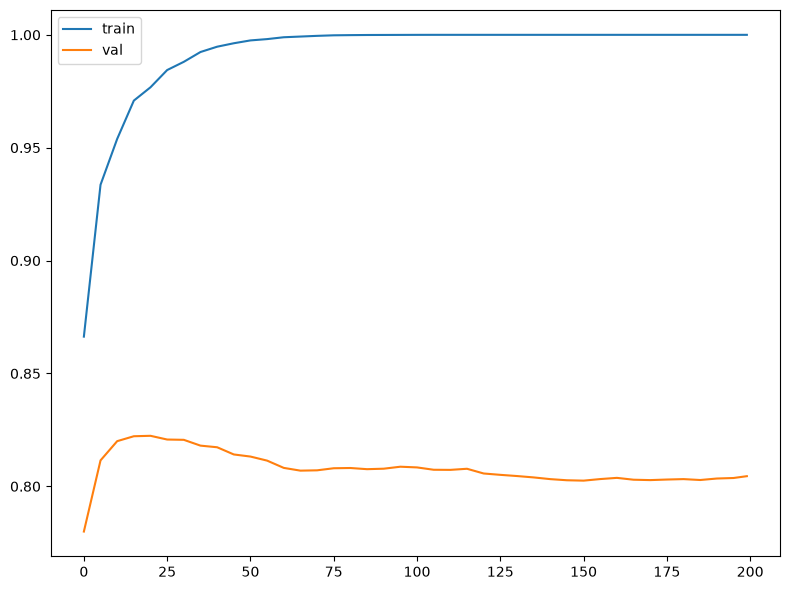

In [64]:
df_score = parse_xgb_output(output)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(df_score["n_iter"], df_score["train_auc"], label="train")
ax.plot(df_score["n_iter"], df_score["val_auc"], label="val")

ax.legend()

plt.tight_layout()

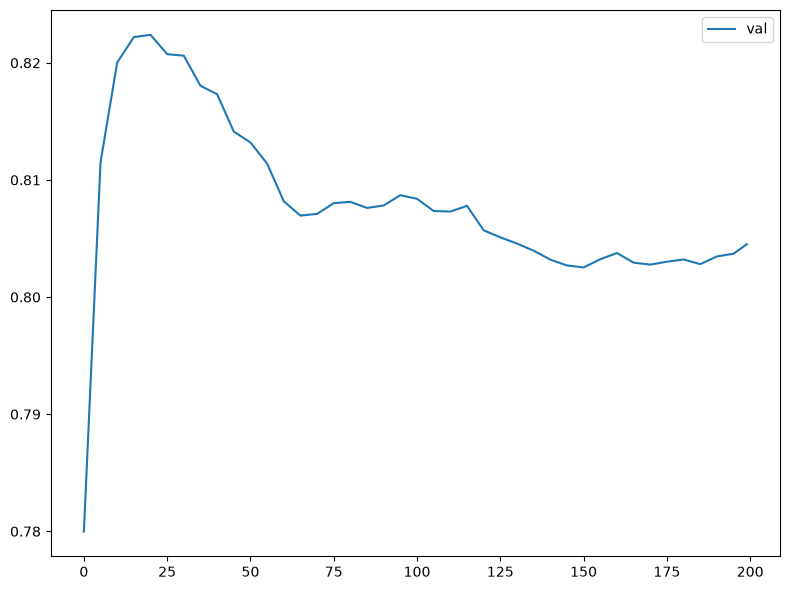

In [65]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(df_score["n_iter"], df_score["val_auc"], label="val")

ax.legend()

plt.tight_layout()

## XGBoost tuning

1. `eta` - the learning rate. It controls the size of the step each next model takes when correcting the errors of the previous ones.
2. `max_depth` - the maximum depth of each tree.
3. `min_child_weight` - the minimal size of a leaf, the analogue of `min_samples_leaf` in random forest.

XGBoost has many more parameters - we tune only these three, in this order: first `eta`, then `max_depth`, then `min_child_weight`. For each parameter we train a model per value, parse the monitoring output with the `parse_xgb_output` function from the previous unit, and compare the validation AUC curves.

In [66]:
scores = {}
watchlist = [(dtrain, "train"), (dval, "val")]

In [67]:
%%capture output

MAX_DEPTH = 6
MIN_SAMPLES = 1

xgb_params = {
    "eta": 0.01,
    "max_depth": MAX_DEPTH,
    "min_child_weight": MIN_SAMPLES,
    
    "objective": "binary:logistic",
    "eval_metric": "auc",
    
    "nthread": 8,
    "seed": SEED,
    "verbosity": 1
}

model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=200,
    evals=watchlist
)

In [68]:
key = f"eta={xgb_params["eta"]}"
scores[key] = parse_xgb_output(output)
print(key)
scores.items()

eta=0.01


dict_items([('eta=0.01',      n_iter  train_auc  val_auc
0         0    0.86632  0.77998
1         1    0.86641  0.77980
2         2    0.86654  0.77977
3         3    0.86851  0.77854
4         4    0.86922  0.77835
..      ...        ...      ...
195     195    0.93746  0.81478
196     196    0.93763  0.81477
197     197    0.93786  0.81488
198     198    0.93801  0.81484
199     199    0.93809  0.81512

[200 rows x 3 columns])])

In [69]:
model

In [70]:
MAX_DEPTH = 6
MIN_SAMPLES = 1

xgb_params = {
    "eta": 0.01,
    "max_depth": MAX_DEPTH,
    "min_child_weight": MIN_SAMPLES,
    
    "objective": "binary:logistic",
    "eval_metric": "auc",
    
    "nthread": 8,
    "seed": SEED,
    "verbosity": 1
}

evals_result = {}

model = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=200,
    evals=watchlist,
    evals_result=evals_result,
    verbose_eval=False,
)

In [71]:
evals_result["val"]["auc"]

[0.7799792933084692,
 0.7798037102516286,
 0.7797673827226272,
 0.7785413286188273,
 0.7783475817974861,
 0.7782083262696471,
 0.7779903610956382,
 0.7778995422731346,
 0.7787350754401685,
 0.778877358262091,
 0.7783808820324042,
 0.7830641059795113,
 0.7830459422150106,
 0.7828854956285873,
 0.7830247511564263,
 0.7827674311593326,
 0.7833668353878569,
 0.7850772565450098,
 0.7858310527717904,
 0.7867755685258289,
 0.7871933351093459,
 0.7883770070959774,
 0.7922640526991354,
 0.793959337385871,
 0.7945708507907292,
 0.7957060860720254,
 0.7969957133515778,
 0.7985244968637233,
 0.7990966554454966,
 0.7999231067302802,
 0.8000048436705335,
 0.8003953646072994,
 0.8008312949553171,
 0.8004740742534693,
 0.7999987890823667,
 0.7997142234385217,
 0.7997868784965246,
 0.7999775980237824,
 0.7994962582645129,
 0.7987969533312345,
 0.7986576978033955,
 0.7981793853382093,
 0.79778583710736,
 0.797440725581846,
 0.7970320408805793,
 0.7968988399409073,
 0.7961843985372115,
 0.796335763241384

In [72]:
key = f"eta={xgb_params["eta"]}"
scores[key] = evals_result["val"]["auc"]
scores

{'eta=0.01': [0.7799792933084692,
  0.7798037102516286,
  0.7797673827226272,
  0.7785413286188273,
  0.7783475817974861,
  0.7782083262696471,
  0.7779903610956382,
  0.7778995422731346,
  0.7787350754401685,
  0.778877358262091,
  0.7783808820324042,
  0.7830641059795113,
  0.7830459422150106,
  0.7828854956285873,
  0.7830247511564263,
  0.7827674311593326,
  0.7833668353878569,
  0.7850772565450098,
  0.7858310527717904,
  0.7867755685258289,
  0.7871933351093459,
  0.7883770070959774,
  0.7922640526991354,
  0.793959337385871,
  0.7945708507907292,
  0.7957060860720254,
  0.7969957133515778,
  0.7985244968637233,
  0.7990966554454966,
  0.7999231067302802,
  0.8000048436705335,
  0.8003953646072994,
  0.8008312949553171,
  0.8004740742534693,
  0.7999987890823667,
  0.7997142234385217,
  0.7997868784965246,
  0.7999775980237824,
  0.7994962582645129,
  0.7987969533312345,
  0.7986576978033955,
  0.7981793853382093,
  0.79778583710736,
  0.797440725581846,
  0.7970320408805793,
  0

In [73]:
scores = {}
watchlist = [(dtrain, "train"), (dval, "val")]

MAX_DEPTH = 6
MIN_SAMPLES = 1
NUM_BOOSTS = 200

eta_values = [0.01, 0.05, 0.1, 0.3, 1.0]

for e in eta_values:
    xgb_params = {
        "eta": e,
        "max_depth": MAX_DEPTH,
        "min_child_weight": MIN_SAMPLES,
        
        "objective": "binary:logistic",
        "eval_metric": "auc",
        
        "nthread": 8,
        "seed": SEED,
        "verbosity": 1
    }

    evals_result = {}

    model = xgb.train(
        xgb_params,
        dtrain,
        num_boost_round=NUM_BOOSTS,
        evals=watchlist,
        evals_result=evals_result,
        verbose_eval=False,
    )

    scores[f"eta={e}"] = evals_result["val"]["auc"]

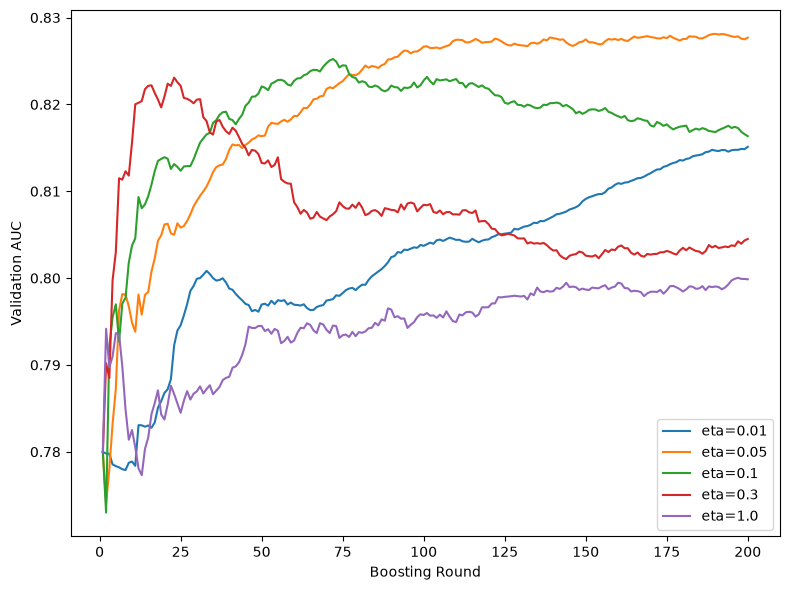

In [74]:
fig, ax = plt.subplots(figsize=(8, 6))

for key, val_auc_score in scores.items():
    ax.plot(range(1, NUM_BOOSTS + 1), val_auc_score, label=key)

ax.set_xlabel("Boosting Round")
ax.set_ylabel("Validation AUC")
ax.legend()

plt.tight_layout()

In [75]:
for key, val_auc_score in scores.items():
    print(f"{key} --> {val_auc_score[-1]}")

eta=0.01 --> 0.8151170957351481
eta=0.05 --> 0.8276955026519096
eta=0.1 --> 0.816343149838948
eta=0.3 --> 0.8045064299726332
eta=1.0 --> 0.7998655881426945


Let's consider `eta = 0.05` (Note: In the learning materials, it use `eta = 0.1`)

In [76]:
scores = {}
watchlist = [(dtrain, "train"), (dval, "val")]

ETA = 0.05
MIN_SAMPLES = 1
NUM_BOOSTS = 200

max_depths = [6, 3, 4, 10]

for d in max_depths:
    xgb_params = {
        "eta": ETA,
        "max_depth": d,
        "min_child_weight": MIN_SAMPLES,
        
        "objective": "binary:logistic",
        "eval_metric": "auc",
        
        "nthread": 8,
        "seed": SEED,
        "verbosity": 1
    }

    evals_result = {}

    model = xgb.train(
        xgb_params,
        dtrain,
        num_boost_round=NUM_BOOSTS,
        evals=watchlist,
        evals_result=evals_result,
        verbose_eval=False,
    )

    scores[f"max_depth={d}"] = evals_result["val"]["auc"]

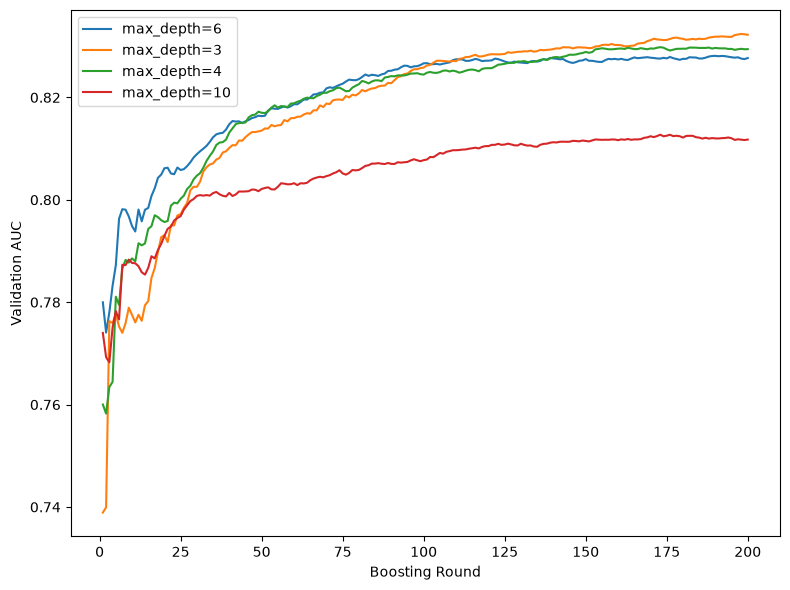

In [77]:
fig, ax = plt.subplots(figsize=(8, 6))

for key, val_auc_score in scores.items():
    ax.plot(range(1, NUM_BOOSTS + 1), val_auc_score, label=key)

ax.set_xlabel("Boosting Round")
ax.set_ylabel("Validation AUC")
ax.legend()

plt.tight_layout()

In [78]:
scores.pop("max_depth=10")
scores.keys()

dict_keys(['max_depth=6', 'max_depth=3', 'max_depth=4'])

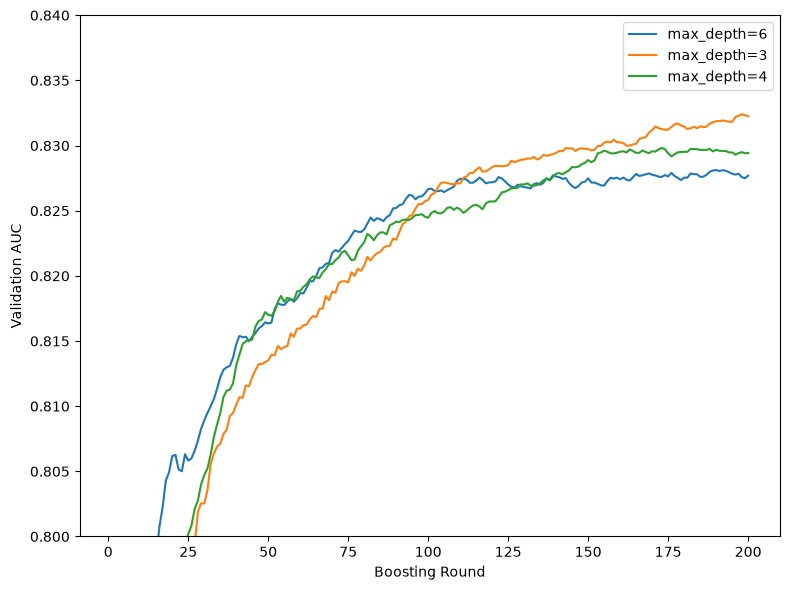

In [79]:
fig, ax = plt.subplots(figsize=(8, 6))

for key, val_auc_score in scores.items():
    ax.plot(range(1, NUM_BOOSTS + 1), val_auc_score, label=key)

ax.set_ylim(0.8, 0.84)
ax.set_xlabel("Boosting Round")
ax.set_ylabel("Validation AUC")
ax.legend()

plt.tight_layout()

In [80]:
for key, val_auc_score in scores.items():
    print(f"{key} --> {val_auc_score[-1]}")

max_depth=6 --> 0.8276955026519096
max_depth=3 --> 0.8322485529534281
max_depth=4 --> 0.8294331694558136


`max_depth = 3` gives the highest and most stable validation AUC

In [81]:
scores = {}
watchlist = [(dtrain, "train"), (dval, "val")]

ETA = 0.05
MAX_DEPTH = 3
NUM_BOOSTS = 200

min_child_weights = [1, 5, 10, 30]

for w in min_child_weights:
    xgb_params = {
        "eta": ETA,
        "max_depth": MAX_DEPTH,
        "min_child_weight": w,
        
        "objective": "binary:logistic",
        "eval_metric": "auc",
        
        "nthread": 8,
        "seed": SEED,
        "verbosity": 1
    }

    evals_result = {}

    model = xgb.train(
        xgb_params,
        dtrain,
        num_boost_round=NUM_BOOSTS,
        evals=watchlist,
        evals_result=evals_result,
        verbose_eval=False,
    )

    scores[f"min_child_weight={w}"] = evals_result["val"]["auc"]

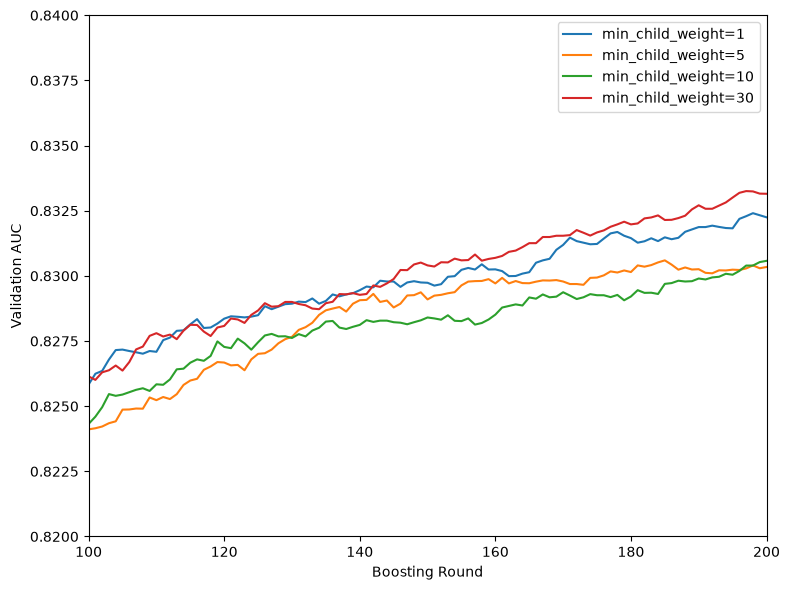

In [82]:
fig, ax = plt.subplots(figsize=(8, 6))

for key, val_auc_score in scores.items():
    ax.plot(range(1, NUM_BOOSTS + 1), val_auc_score, label=key)

ax.set_xlim(100, 200)
ax.set_ylim(0.82, 0.84)
ax.set_xlabel("Boosting Round")
ax.set_ylabel("Validation AUC")
ax.legend()

plt.tight_layout()

In [83]:
for key, val_auc_score in scores.items():
    print(f"{key} --> {val_auc_score[-1]}")

min_child_weight=1 --> 0.8322485529534281
min_child_weight=5 --> 0.8303413576808506
min_child_weight=10 --> 0.8305774866193602
min_child_weight=30 --> 0.8331506865902981


Values are relatively close with one another. Keep `min_child_weight` = 1

In [84]:
# Final model

ETA = 0.05
MAX_DEPTH = 3
MIN_SAMPLES = 1
NUM_BOOSTS = 200

xgb_params = {
    "eta": ETA,
    "max_depth": MAX_DEPTH,
    "min_child_weight": MIN_SAMPLES,
    
    "objective": "binary:logistic",
    "eval_metric": "auc",
    
    "nthread": 8,
    "seed": SEED,
    "verbosity": 1
}

model = xgb.train(
    xgb_params, 
    dtrain, 
    num_boost_round=NUM_BOOSTS
)

In [85]:
y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)

0.832248552953428

## Final model selection

In [100]:
train_dict = df_train.fillna(0).to_dict(orient="records")
val_dict = df_val.fillna(0).to_dict(orient="records")

In [101]:
train_dict[0]

{'seniority': 10,
 'home': 'owner',
 'time': 36,
 'age': 36,
 'marital': 'married',
 'records': 'no',
 'job': 'freelance',
 'expenses': 75,
 'income': 0.0,
 'assets': 10000.0,
 'debt': 0.0,
 'amount': 1000,
 'price': 1400}

In [102]:
val_dict[0]

{'seniority': 6,
 'home': 'rent',
 'time': 36,
 'age': 31,
 'marital': 'separated',
 'records': 'no',
 'job': 'fixed',
 'expenses': 49,
 'income': 140.0,
 'assets': 0.0,
 'debt': 0.0,
 'amount': 550,
 'price': 999}

In [103]:
DT_MAX_DEPTH = 6
DT_MIN_SAMPLES_LEAF = 15

model_dt = make_pipeline(
    DictVectorizer(sparse=False),
    DecisionTreeClassifier(
        max_depth=DT_MAX_DEPTH,
        min_samples_leaf=DT_MIN_SAMPLES_LEAF,
        random_state=SEED
    )
)

model_dt.fit(train_dict, y_train)

y_pred = model_dt.predict_proba(val_dict)[:, 1]
auc_dt = roc_auc_score(y_val, y_pred)
auc_dt

0.7850802838390931

In [104]:
model_dt

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dictvectorizer', ...), ('decisiontreeclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"sparse sparse: bool, default=TrueWhether transform should produce scipy.sparse matrices.",False
,"dtype dtype: dtype, default=np.float64The type of feature values. Passed to Numpy array/scipy.sparse matrixconstructors as the dtype argument.",<class 'numpy.float64'>
,"separator separator: str, default=""=""Separator string used when constructing new features for one-hotcoding.",'='
,"sort sort: bool, default=TrueWhether ``feature_names_`` and ``vocabulary_`` should besorted when fitting.",True
Name,Type,Value


In [105]:
RF_NUM_TREES = 200
RF_MAX_DEPTH = 10
RF_MIN_SAMPLES = 3

model_rf = make_pipeline(
    DictVectorizer(sparse=False),
    RandomForestClassifier(
        n_estimators=RF_NUM_TREES,
        max_depth=RF_MAX_DEPTH,
        min_samples_leaf=RF_MIN_SAMPLES,
        random_state=SEED
    )
)

model_rf.fit(train_dict, y_train)

y_pred = model_rf.predict_proba(val_dict)[:, 1]
auc_rf = roc_auc_score(y_val, y_pred)
auc_rf

0.8253039403259791

In [106]:
model_rf

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('dictvectorizer', ...), ('randomforestclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"sparse sparse: bool, default=TrueWhether transform should produce scipy.sparse matrices.",False
,"dtype dtype: dtype, default=np.float64The type of feature values. Passed to Numpy array/scipy.sparse matrixconstructors as the dtype argument.",<class 'numpy.float64'>
,"separator separator: str, default=""=""Separator string used when constructing new features for one-hotcoding.",'='
,"sort sort: bool, default=TrueWhether ``feature_names_`` and ``vocabulary_`` should besorted when fitting.",True
Name,Type,Value


In [111]:
features = list(model_dt[0].get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [112]:
ETA = 0.05
MAX_DEPTH = 3
MIN_SAMPLES = 1
NUM_BOOSTS = 200

xgb_params = {
    "eta": ETA,
    "max_depth": MAX_DEPTH,
    "min_child_weight": MIN_SAMPLES,
    
    "objective": "binary:logistic",
    "eval_metric": "auc",
    
    "nthread": 8,
    "seed": SEED,
    "verbosity": 1
}

model_xgb = xgb.train(
    xgb_params, 
    dtrain, 
    num_boost_round=NUM_BOOSTS
)

y_pred = model_xgb.predict(dval)
auc_xgb = roc_auc_score(y_val, y_pred)
auc_xgb

0.832248552953428

Comparison:

- Decision tree --> 0.78508
- Random forest --> 0.82530
- XGBoost       --> 0.83225

XGBoost wins with an AUC of about 0.832, ahead of random forest at about 0.825 and the single decision tree at about 0.785. This is a typical outcome: boosted trees are very strong on tabular data. The price is that XGBoost has many hyperparameters and can overfit quickly, so it needs more attention during tuning than random forest, which works well almost out of the box.

In [114]:
df_full_train

,status,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,ok,22,owner,48,48,married,no,fixed,60,110.0,3000.0,0.0,1000,1460
1,default,8,other,60,41,married,no,freelance,45,62.0,0.0,0.0,1800,2101
2,ok,2,parents,36,19,married,no,fixed,35,162.0,4000.0,100.0,400,570
3,ok,1,owner,12,61,married,no,others,45,103.0,20000.0,0.0,300,650
4,ok,13,owner,60,27,married,no,fixed,35,253.0,7000.0,0.0,1060,1750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3558,default,4,owner,60,47,married,no,freelance,75,0.0,13500.0,0.0,1900,1976
3559,ok,2,rent,60,28,single,no,fixed,45,101.0,0.0,0.0,1300,1333
3560,ok,2,parents,36,25,single,no,fixed,35,110.0,0.0,0.0,500,1200
3561,ok,4,other,60,25,single,no,fixed,35,162.0,0.0,0.0,1800,2999


In [115]:
# Final model training

y_full_train = (df_full_train["status"] == "default").astype("int").values
df_full_train.drop("status", axis=1, inplace=True)

In [116]:
df_full_train

,seniority,home,time,age,marital,records,job,expenses,income,assets,debt,amount,price
0,22,owner,48,48,married,no,fixed,60,110.0,3000.0,0.0,1000,1460
1,8,other,60,41,married,no,freelance,45,62.0,0.0,0.0,1800,2101
2,2,parents,36,19,married,no,fixed,35,162.0,4000.0,100.0,400,570
3,1,owner,12,61,married,no,others,45,103.0,20000.0,0.0,300,650
4,13,owner,60,27,married,no,fixed,35,253.0,7000.0,0.0,1060,1750
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3558,4,owner,60,47,married,no,freelance,75,0.0,13500.0,0.0,1900,1976
3559,2,rent,60,28,single,no,fixed,45,101.0,0.0,0.0,1300,1333
3560,2,parents,36,25,single,no,fixed,35,110.0,0.0,0.0,500,1200
3561,4,other,60,25,single,no,fixed,35,162.0,0.0,0.0,1800,2999


In [117]:
y_full_train

array([0, 1, 0, ..., 0, 0, 1], shape=(3563,))

In [122]:
full_train_dict = df_full_train.fillna(0).to_dict(orient="records")
test_dict = df_test.fillna(0).to_dict(orient="records")

dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(full_train_dict)
X_test = dv.transform(test_dict)

dfulltrain = xgb.DMatrix(
    X_full_train, 
    label=y_full_train, 
    feature_names=list(dv.get_feature_names_out())
)
dtest = xgb.DMatrix(
    X_test,
    feature_names=list(dv.get_feature_names_out())
)

In [124]:
ETA = 0.05
MAX_DEPTH = 3
MIN_SAMPLES = 1
NUM_BOOSTS = 200

xgb_params = {
    "eta": ETA,
    "max_depth": MAX_DEPTH,
    "min_child_weight": MIN_SAMPLES,
    
    "objective": "binary:logistic",
    "eval_metric": "auc",
    
    "nthread": 8,
    "seed": SEED,
    "verbosity": 1
}

model = xgb.train(
    xgb_params, 
    dfulltrain, 
    num_boost_round=NUM_BOOSTS
)

In [125]:
y_pred = model.predict(dtest)
roc_auc_score(y_test, y_pred)

0.8351681247250868

Result is 0.83516, a little higher than 0.83225 from training. :)

## Summary

- Decision trees learn if-then-else rules from data.
- Finding the best split: select the least impure split. This algorithm can overfit, that's why we control it by limiting the max depth and the size of the group.
- Random forest is a way of combininig multiple decision trees. It should have a diverse set of models to make good predictions.
- Gradient boosting trains model sequentially: each model tries to fix errors of the previous model. XGBoost is an implementation of gradient boosting.

## Supplementary

- For this dataset we didn't do EDA or feature engineering. You can do it to get more insights into the problem.
- For random forest, there are more parameters that we can tune. Check `max_features` and `bootstrap`.
- There's a variation of random forest caled "extremely randomized trees", or "extra trees". Instead of selecting the best split among all possible thresholds, it selects a few thresholds randomly and picks the best one among them. Because of that extra trees never overfit. In Scikit-Learn, they are implemented in `ExtraTreesClassifier`. Try it for this project.
- XGBoost can deal with NAs - we don't have to do `fillna` for it. Check if not filling NA's help improve performance.
- Experiment with other XGBoost parameters: `subsample` and `colsample_bytree`.
- When selecting the best split, decision trees find the most useful features. This information can be used for understanding which features are more important than others. See example here for [random forest](https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html) (it's the same for plain decision trees) and for [xgboost](https://stackoverflow.com/questions/37627923/how-to-get-feature-importance-in-xgboost).
- Trees can also be used for solving the regression problems: check `DecisionTreeRegressor`, `RandomForestRegressor` and the `objective=reg:squarederror` parameter for XGBoost.